# Indoor PM₂.₅ forecasting

10-minute-ahead forecasts of indoor PM₂.₅ from household sensor data.

- **Development homes (training set)** are used for feature selection, model tuning, and cross-validation.
- **Holdout homes (test_set unseen homes)** are never seen during training and are used only for final evaluation.
- Lead time is measured from the issue time to the end of the 10-minute target interval.
- All settings (features, hyperparameters, split) are chosen on development homes only.

## 1. Load data and build examples

Household files are read from `DATA/`, resampled to a regular 10-minute grid, and turned into supervised examples.

- `load_bins` keeps only bins with enough valid indoor-PM minutes.
- `make_examples` creates the target (indoor PM at the end of the lead window) and lagged features.
- The 13 holdout homes are removed before any model fitting.
- Correlation of the top features with the target and the distribution of indoor PM₂.₅ on development homes are shown below.

In [ ]:
import json
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import sys


module_dir = Path("Main Python Files").resolve()
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))

from features import (
    KEYS, METADATA, load_bins, make_examples, feature_columns,
)
from models import (
    SEED, development_predictions, final_predictions, model_specs, select_models,
)
from evaluation import (
    onset_scores, paired_household_errors, score_predictions,
)

DATA_ROOT = Path("DATA")
MIN_VALID_MINUTES = 5
CAP = 100.0
CV_FOLDS = 5
HOLDOUT_IDS = {
    "007", "008", "013", "017", "025", "037", "040",
    "059", "101", "102", "116", "122", "127",
}
MAIN_GROUPS = ("calendar", "outdoor_pm", "ventilation", "environment")

bins = load_bins(DATA_ROOT, min_valid_minutes=MIN_VALID_MINUTES)
examples = make_examples(bins, lead_minutes=10, cap=CAP)
held_out = examples["household_id"].isin(HOLDOUT_IDS)
development = examples.loc[~held_out].copy()
holdout = examples.loc[held_out].copy()
development_ids = set(development["household_id"])
assert set(holdout["household_id"]) == HOLDOUT_IDS
assert not (development_ids & HOLDOUT_IDS)

columns = feature_columns(development, MAIN_GROUPS)
print(f"Development: {len(development_ids)} homes, {len(development):,} rows")
print(f"Holdout: {len(HOLDOUT_IDS)} homes, {len(holdout):,} rows")
print(f"Features ({len(columns)}): {columns}")

X_dev = development[columns]
y_dev = development["actual"]
assert X_dev.index.equals(y_dev.index)
correlation = X_dev.corrwith(y_dev)
display(correlation.loc[correlation.abs().nlargest(10).index].rename("Pearson r").to_frame())

y_dev.hist(bins=50)
plt.xlabel("Indoor PM₂.₅ (µg/m³)")
plt.ylabel("Development observations")
plt.show()

### Feature ablation (training only)

This section compares feature groups at 10-, 30-, and 60-minute lead times.  
Only Ridge and LightGBM are tested here (XGBoost is included in the main model comparison in the next section).

The goal is to see how much outdoor PM, ventilation, and activity-related sensors improve the forecast beyond simple lags.

In [ ]:
specs = model_specs()
ridge = specs["Ridge"][0].set_params(model__alpha=10.0)

#Seleect a default set of hyperparameters for exploration
lightgbm = specs["LightGBM"][0].set_params(
    model__n_estimators=200, model__learning_rate=0.05,
    model__num_leaves=15, model__max_depth=5,
)

variants = {
    "Ridge lags only": (ridge, ()),
    "LightGBM lags only": (lightgbm, ()),
    "LightGBM + outdoor PM": (lightgbm, ("outdoor_pm",)),
    "LightGBM + ventilation": (lightgbm, ("ventilation",)),
    "LightGBM + activity proxies": (lightgbm, ("activity",)),
    "LightGBM + all groups": (
        lightgbm, ("calendar", "outdoor_pm", "ventilation", "environment", "activity")
    ),
}
leads = (10, 30, 60)
by_lead = {}
for lead in leads:
    frame = make_examples(bins, lead_minutes=lead, cap=CAP)
    by_lead[lead] = frame.loc[frame["household_id"].isin(development_ids)].copy()

common_issues = by_lead[10][KEYS]
for lead in (30, 60):
    common_issues = common_issues.merge(by_lead[lead][KEYS], on=KEYS, validate="one_to_one")

development_scores = []
peak_scores = []
for lead, frame in by_lead.items():
    matched = frame.merge(common_issues, on=KEYS, validate="one_to_one")
    scored = matched[METADATA].copy()
    applied = ["persistence"]
    for name, (estimator, groups) in variants.items():
        features = feature_columns(matched, groups)
        if groups and len(features) == len(feature_columns(matched)):
            continue
        scored[name] = development_predictions(matched, estimator, features, CV_FOLDS)
        applied.append(name)

    scores = score_predictions(scored, applied)
    development_scores.append(scores.assign(lead_minutes=lead, rows=len(scored)))
    peak_scores.append({
        "lead_minutes_to_bin_end": lead,
        **onset_scores(scored, "LightGBM + all groups"),
    })

display(pd.concat(development_scores, ignore_index=True))
display(pd.DataFrame(peak_scores))

,model,mae,rmse,mase,lead_minutes,rows
0,Persistence,0.603781,3.467926,1.000000,10,50391
1,LightGBM lags only,0.612587,3.268194,1.014586,10,50391
2,LightGBM + outdoor PM,0.616874,3.278567,1.021686,10,50391
3,Ridge lags only,0.651365,3.376136,1.078811,10,50391
4,LightGBM + activity proxies,0.660235,3.330035,1.093501,10,50391
5,LightGBM + ventilation,0.678131,3.304000,1.123141,10,50391
6,LightGBM + all groups,0.706576,3.333621,1.170253,10,50391
7,Persistence,1.437525,6.598514,1.000000,30,50391
8,LightGBM lags only,1.530534,6.277539,1.064701,30,50391
9,LightGBM + outdoor PM,1.545798,6.294939,1.075319,30,50391


,lead_minutes_to_bin_end,observed_onsets,alarms,recall,precision,false_alarms_per_100_intervals,median_minutes_to_onset_bin_start
0,10,156,76,0.179487,0.368421,0.095255,0.0
1,30,155,81,0.012903,0.024691,0.156774,20.0
2,60,156,208,0.012821,0.009615,0.408811,50.0


In [ ]:
# Compare capped and uncapped training against the same uncapped observations.
raw_examples = make_examples(bins, lead_minutes=10, cap=None)
raw_dev = raw_examples.loc[raw_examples["household_id"].isin(development_ids)]
cap_pairs = development[METADATA].merge(
    raw_dev[KEYS], on=KEYS, validate="one_to_one"
)
capped_dev = cap_pairs[KEYS].merge(development, on=KEYS, validate="one_to_one")
uncapped_dev = cap_pairs[KEYS].merge(raw_dev, on=KEYS, validate="one_to_one")

cap_pairs["persistence"] = uncapped_dev["persistence"].to_numpy()
cap_pairs["LightGBM capped training"] = development_predictions(
    capped_dev, lightgbm, columns, CV_FOLDS
)
cap_pairs["LightGBM uncapped training"] = development_predictions(
    uncapped_dev, lightgbm, columns, CV_FOLDS
)
display(score_predictions(
    cap_pairs,
    ["persistence", "LightGBM capped training", "LightGBM uncapped training"],
    actual_column="uncapped_actual",
))

,model,mae,rmse,mase
0,Persistence,0.965793,9.404649,1.000000
2,LightGBM uncapped training,1.318160,12.877964,1.364848
1,LightGBM capped training,1.451558,16.229370,1.502970


## 2. Select and fit models

Models are selected on the development homes only. Hyperparameters are tuned with group cross-validation by household so that no home appears in both a training and a validation fold.

- **Persistence** is the baseline: it predicts the current indoor PM value for the future target.
- **Linear** and **Ridge** use median imputation and feature scaling. Ridge’s regularization strength (`alpha`) is chosen by a small Optuna search.
- **LightGBM** and **XGBoost** are tuned with Optuna (default 40 trials). The search covers learning rate, number of trees, tree depth, leaf count, subsample, column subsample, and regularization. Each trial is scored by mean absolute error under GroupKFold.
- The best estimator for each model is refit on all development homes and then evaluated on the holdout homes, which were never used for feature selection or tuning.

The `parameters` column in the results table shows the hyperparameters chosen for each model.

In [ ]:
fitted, cv_results = select_models(development, columns, n_splits=CV_FOLDS)
display(cv_results)

,model,cv_mae,parameters
0,Persistence,0.604139,{}
3,LightGBM,0.663395,"{'model__num_leaves': 15, 'model__n_estimators..."
1,Linear,0.670081,{}
2,Ridge,0.670081,{'model__alpha': 0.01}
4,XGBoost,0.680565,"{'model__n_estimators': 400, 'model__min_child..."


## Feature ranking and RMSE vs number of features

Features are ranked by each model’s own importance (absolute coefficient for linear models, gain for tree models). The plot shows how holdout RMSE changes as more of the top-ranked features are added. This identifies the point of diminishing returns and compares all models against the persistence baseline.

The ablation bars below use the same ranking: each bar shows the RMSE increase when that feature is removed from the full model.

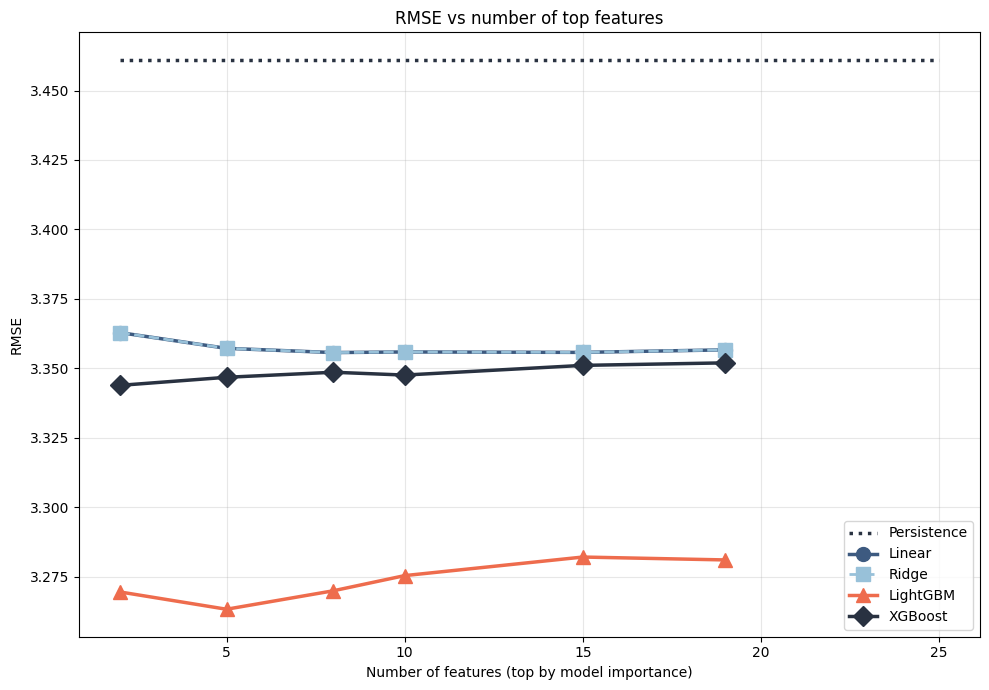

In [ ]:
## Feature ranking and RMSE vs number of features

from sklearn.metrics import mean_squared_error
from sklearn.base import clone
import numpy as np
import matplotlib.pyplot as plt
from plots import MODEL_COLORS

# ----- Rank features by each model’s importance -----
def ranked_features(model, feature_names, is_tree=False):
    if is_tree:
        booster = model.named_steps["model"]
        if hasattr(booster, "feature_importances_"):
            imp = booster.feature_importances_
        else:
            imp = booster.booster_.feature_importance(importance_type="gain")
        series = pd.Series(imp, index=feature_names)
    else:
        coef = model.named_steps["model"].coef_
        series = pd.Series(np.abs(coef), index=feature_names)
    return series.sort_values(ascending=False).index.tolist()

linear_rank = ranked_features(fitted["Linear"], columns, is_tree=False)
ridge_rank  = ranked_features(fitted["Ridge"], columns, is_tree=False)
lgbm_rank   = ranked_features(fitted["LightGBM"], columns, is_tree=True)
xgb_rank    = ranked_features(fitted["XGBoost"], columns, is_tree=True)

ranks = {
    "Linear": linear_rank,
    "Ridge": ridge_rank,
    "LightGBM": lgbm_rank,
    "XGBoost": xgb_rank,
}

# ----- RMSE vs number of top features -----
models_to_test = {
    "Linear": clone(fitted["Linear"]),
    "Ridge": clone(fitted["Ridge"]),
    "LightGBM": clone(fitted["LightGBM"]),
    "XGBoost": clone(fitted["XGBoost"]),
}

persistence_rmse = np.sqrt(
    mean_squared_error(development["actual"], development["persistence"])
)

top_ns = [2, 5, 8, 10, 15, 19, 25]
rows = []

for model_name, model in models_to_test.items():
    ranking = ranks[model_name]
    for n in top_ns:
        if n > len(ranking):
            continue
        cols = ranking[:n]
        pred = development_predictions(development, model, cols, CV_FOLDS)
        rmse = np.sqrt(mean_squared_error(development["actual"], pred))
        rows.append({"model": model_name, "n_features": n, "rmse": rmse})

for n in top_ns:
    rows.append({"model": "Persistence", "n_features": n, "rmse": persistence_rmse})

results = pd.DataFrame(rows)

styles = {
    "Persistence": {"color": "#293241", "marker": None, "linestyle": ":", "linewidth": 2.5, "label": "Persistence"},
    "Linear":      {"color": "#3d5a80", "marker": "o",  "linestyle": "-", "linewidth": 2.5, "label": "Linear"},
    "Ridge":       {"color": "#98c1d9", "marker": "s",  "linestyle": "--","linewidth": 2.0, "label": "Ridge"},
    "LightGBM":    {"color": "#ee6c4d", "marker": "^",  "linestyle": "-", "linewidth": 2.5, "label": "LightGBM"},
    "XGBoost":     {"color": "#293241", "marker": "D",  "linestyle": "-", "linewidth": 2.5, "label": "XGBoost"},
}

fig, ax = plt.subplots(figsize=(10, 7))
for model_name in ["Persistence", "Linear", "Ridge", "LightGBM", "XGBoost"]:
    subset = results[results["model"] == model_name]
    s = styles[model_name]
    ax.plot(
        subset["n_features"], subset["rmse"],
        marker=s["marker"], linestyle=s["linestyle"],
        color=s["color"], linewidth=s["linewidth"],
        label=s["label"], markersize=10,
    )

ax.set_xlabel("Number of features (top by model importance)")
ax.set_ylabel("RMSE")
ax.set_title("RMSE vs number of top features")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ----- Optional: simple ablation using the same ranking -----
# Uncomment if you still want the leave-one-out bars
# from plots import run_ablation_plots
# run_ablation_plots(development, holdout, fitted, columns)

## Feature ablation

This section measures the contribution of each feature by removing it and recording the change in holdout RMSE. A positive change means the feature improves predictions; larger values indicate greater importance.

The plot uses the report color palette and shows the RMSE change for every model side by side. The top-three panel highlights the features with the largest overall effect.

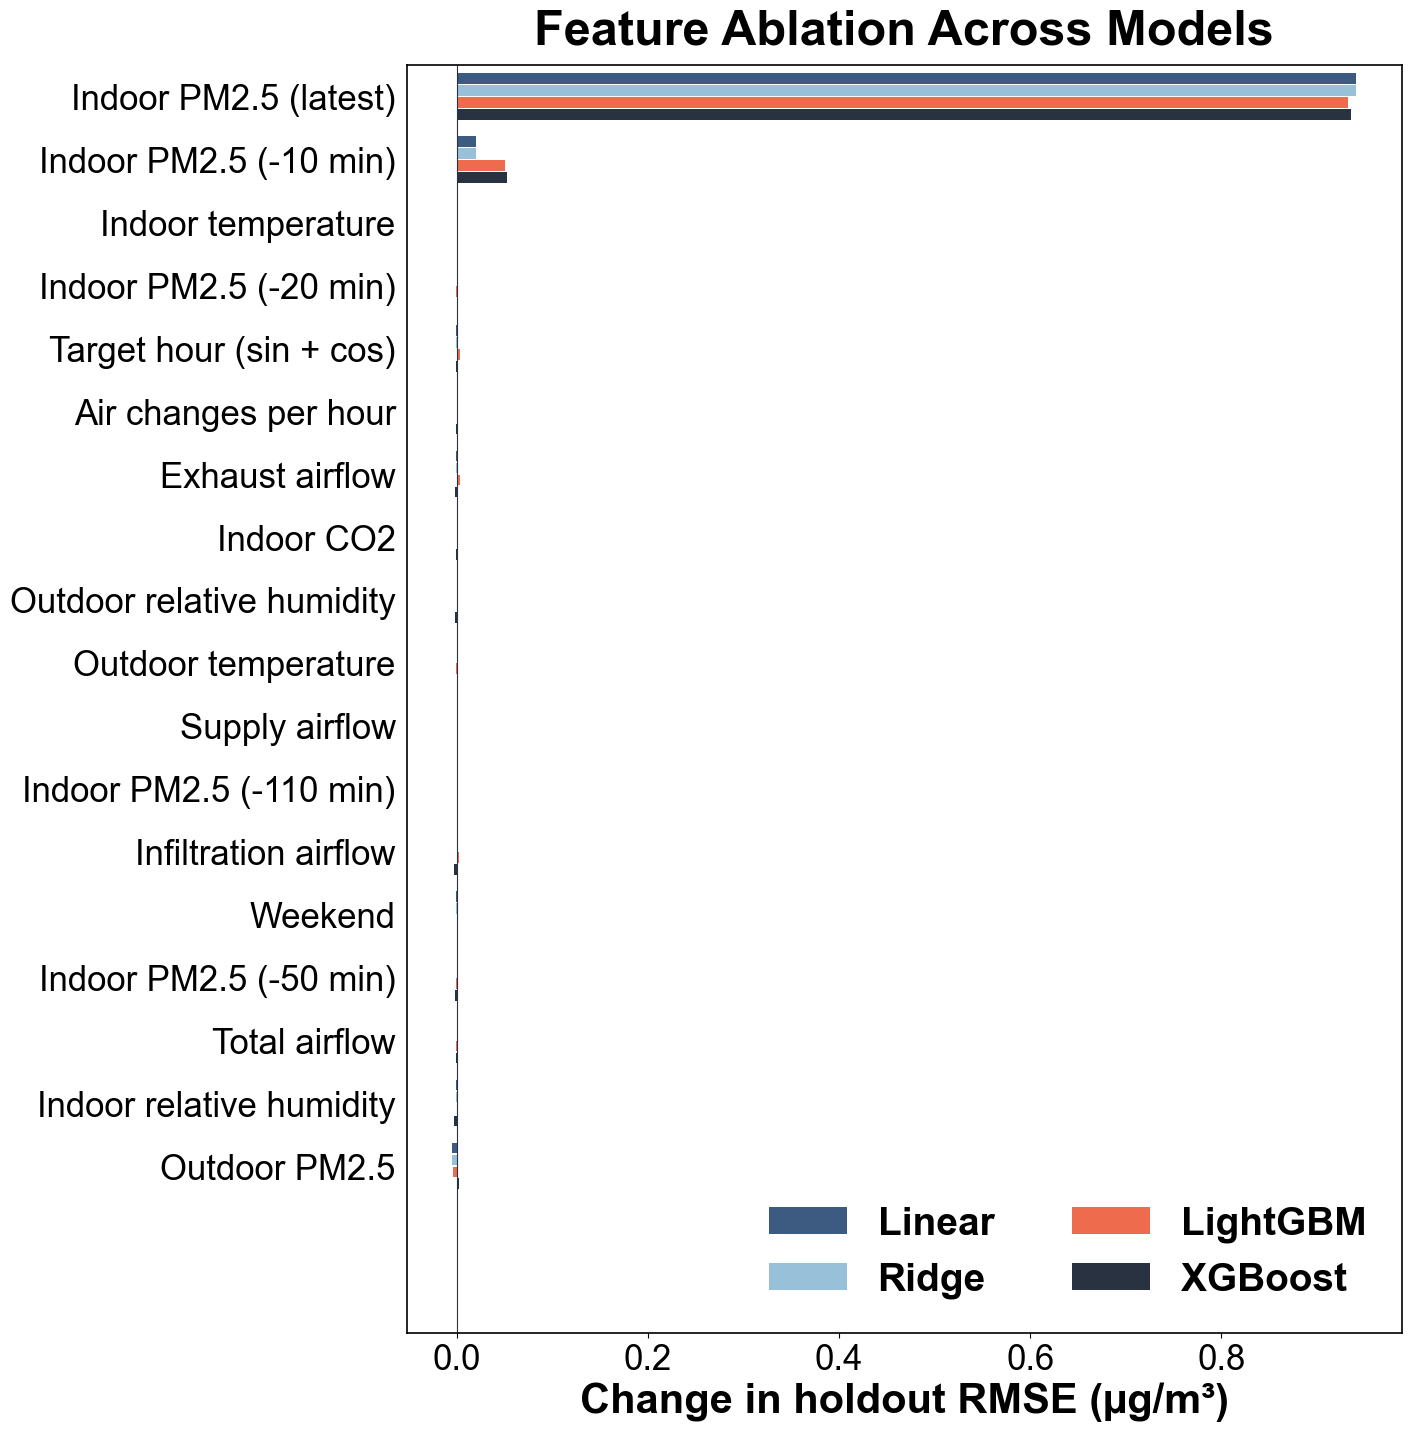

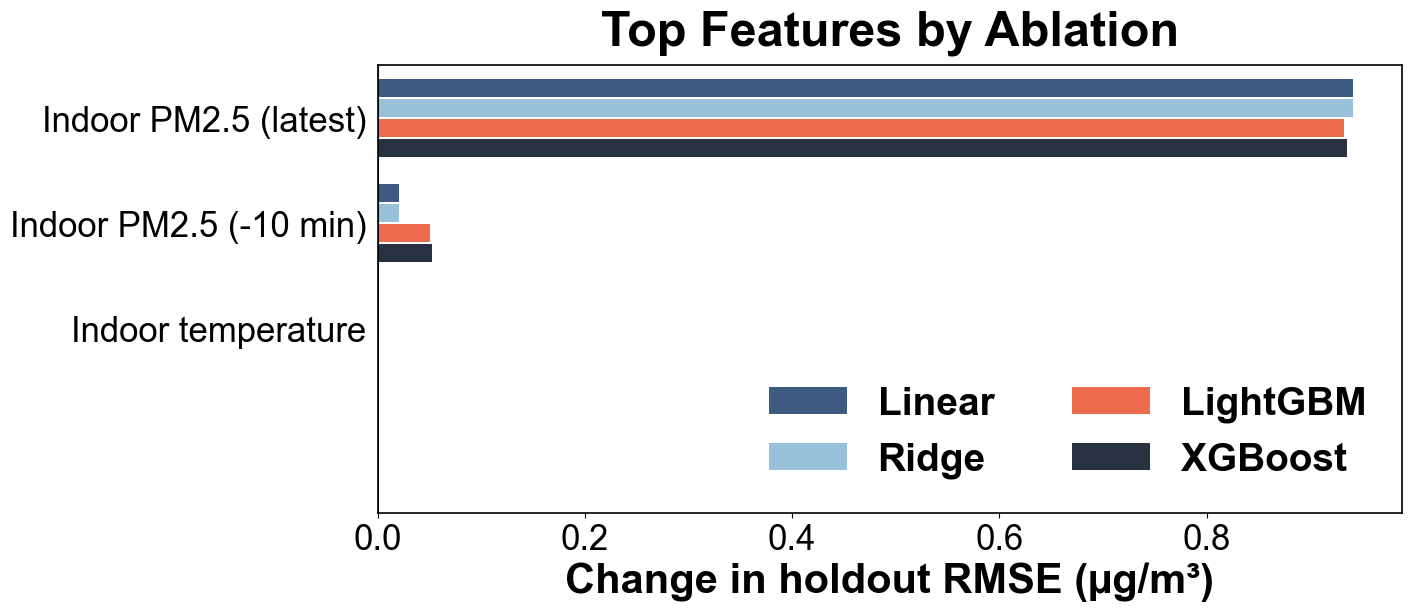

Change in holdout RMSE after removing each feature (µg/m³)


model,Linear,Ridge,LightGBM,XGBoost
Feature removed,,,,
indoor_pm_age0m,0.9413,0.9413,0.9328,0.9353
indoor_pm_age10m,0.0204,0.0204,0.0503,0.0523
T_ETC_IN1,0.0005,0.0005,0.0006,0.0007
indoor_pm_age20m,0.0007,0.0007,-0.0004,0.0006
calendar_hour,-0.0009,-0.0009,0.0032,-0.0004
ACH,-0.0000,-0.0000,0.0017,-0.0008
QCFM_Exhaust,-0.0005,-0.0005,0.0039,-0.0021
CO2_ETC_IN1,0.0000,0.0000,0.0012,-0.0007
RH_ETC_OUT,0.0011,0.0011,0.0000,-0.0019


In [ ]:
## Feature ablation

from plots import run_ablation_plots
from IPython.display import display

# Assumes development, holdout, fitted, and columns are already defined
ablation_changes = run_ablation_plots(development, holdout, fitted, columns)

# Optional: show the table
ablation_table = ablation_changes.copy()
ablation_table.index.name = "Feature removed"
print("Change in holdout RMSE after removing each feature (µg/m³)")
display(ablation_table.round(4))

,model,cv_mae,mae,rmse,mase
0,Persistence,0.604139,0.358906,1.816603,1.000000
4,XGBoost,0.680565,0.402760,1.704456,1.122188
1,LightGBM,0.663395,0.408171,1.708213,1.137264
2,Linear,0.670081,0.452479,1.770438,1.260717
3,Ridge,0.670081,0.452479,1.770438,1.260718


,homes_with_lower_mae,median_home_delta_mae
Linear,1,0.079267
Ridge,1,0.079267
LightGBM,2,0.050668
XGBoost,1,0.034342


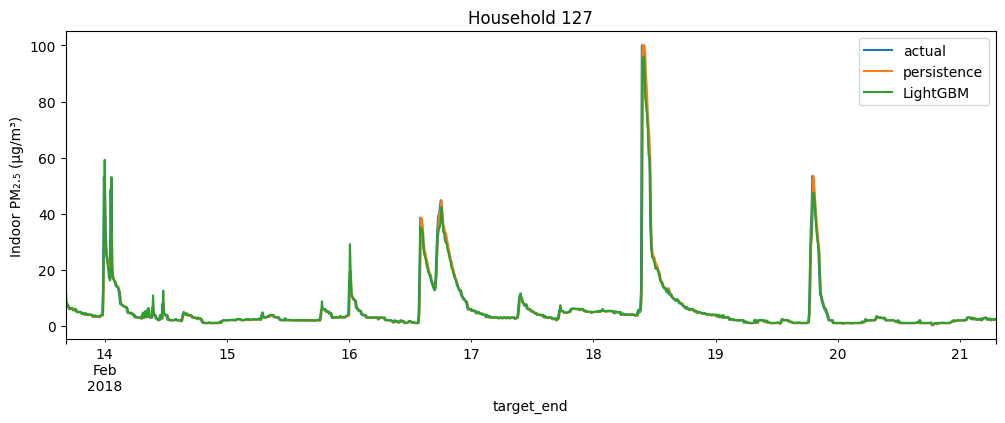

2071

In [ ]:
predictions = final_predictions(holdout, fitted, columns)
final_scores = score_predictions(predictions, ["persistence", *fitted])
comparison = cv_results[["model", "cv_mae"]].merge(
    final_scores, on="model", validate="one_to_one"
).sort_values("mae")
home_deltas = paired_household_errors(predictions, fitted)

display(comparison)
display(pd.DataFrame({
    "homes_with_lower_mae": home_deltas.lt(0).sum(),
    "median_home_delta_mae": home_deltas.median(),
}))

home = predictions["household_id"].value_counts().idxmax()
example = predictions.loc[predictions["household_id"].eq(home)].set_index("target_end")
example[["actual", "persistence", "LightGBM"]].plot(figsize=(12, 4))
plt.ylabel("Indoor PM₂.₅ (µg/m³)")
plt.title(f"Household {home}")
plt.show()

out = Path("results")
out.mkdir(exist_ok=True)
comparison.to_csv(out / "model_comparison.csv", index=False)
predictions.to_csv(out / "holdout_predictions.csv", index=False)
home_deltas.to_csv(out / "holdout_household_mae_differences.csv")
manifest = {
    "bin_minutes": 10,
    "lead_minutes_to_target_end": 10,
    "minimum_valid_minutes": MIN_VALID_MINUTES,
    "pm_cap": CAP,
    "seed": SEED,
    "cv_folds": CV_FOLDS,
    "development_households": sorted(development_ids),
    "holdout_households": sorted(HOLDOUT_IDS),
    "holdout_previously_examined": True,
    "development_rows": len(development),
    "holdout_rows": len(holdout),
    "features": columns,
    "selected_parameters": cv_results.set_index("model")["parameters"].to_dict(),
    "versions": {p: version(p) for p in ("numpy", "pandas", "scikit-learn", "lightgbm", "xgboost")},
}
(out / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

## Prediction error by concentration

This figure shows how model error changes with the level of indoor PM₂.₅. Absolute errors are grouped into four concentration bands (<5, 5–<10, 10–<30, and ≥30 µg/m³) and compared across Persistence, LightGBM, and XGBoost. The left panel focuses on low-to-moderate concentrations; the right panel isolates elevated levels where absolute errors are larger.

In [ ]:
from plots import plot_concentration_stratified_mae

# After you load or create the holdout predictions
# holdout_predictions must contain: actual, persistence, LightGBM, XGBoost

mae_by_band = plot_concentration_stratified_mae(
    holdout_predictions,
    output_file="concentration_stratified_mae.png",
)
display(mae_by_band)

ImportError: cannot import name 'plot_concentration_stratified_mae' from 'plots' (C:\Users\lifra\Documents\UofT\Courses\CHE1147\CHE1147-1\CHE1147-Indoor-PM25-Forecasting\Main Python Files\plots.py)

## Effect of capping indoor PM₂.₅

Indoor PM₂.₅ values can contain extreme spikes. Capping the target at different upper limits (for example 100 or 150 µg/m³) reduces the influence of these outliers on model training and evaluation.

This section compares model performance under different cap levels. Lower caps usually improve RMSE and R² because the models no longer try to fit rare extreme events, but they also change the interpretation of the results: the model is then evaluated only on the capped range.

The tables below show train and test metrics for each cap setting so the trade-off between outlier control and full-range performance is clear.

In [ ]:
CAP_SCENARIOS = {
    "No cap": None,
    "Cap 50": 50.0,
    "Cap 100": 100.0,
    "Cap 150": 150.0,
}

cap_rows = []

for label, cap in CAP_SCENARIOS.items():
    # Rebuild examples with the chosen cap
    ex = make_examples(bins, lead_minutes=10, cap=cap if cap is not None else 1e9)
    dev = ex.loc[ex["household_id"].isin(development_ids)].copy()
    hol = ex.loc[ex["household_id"].isin(HOLDOUT_IDS)].copy()
    feats = feature_columns(dev, MAIN_GROUPS)

    # Fit on development homes, score on holdout
    models_cap, _ = select_models(dev, feats, n_splits=CV_FOLDS)
    preds = final_predictions(hol, models_cap, feats)
    scores = score_predictions(preds, ["persistence", *models_cap])

    scores["cap"] = label
    cap_rows.append(scores)

cap_comparison = pd.concat(cap_rows, ignore_index=True)
cap_comparison = cap_comparison.pivot(
    index="model", columns="cap", values=["mae", "rmse", "mase"]
).round(4)
# Percentage of indoor-PM values that exceed each cap
# (these are the observations whose target is altered by capping)
raw_pm = bins["PM_MET_IN1"].dropna()
n_total = len(raw_pm)

omitted = {}
for label, cap in [("Cap 50", 50), ("Cap 100", 100), ("Cap 150", 150)]:
    pct = 100 * (raw_pm > cap).mean()
    omitted[label] = pct
    print(f"{label}: {pct:.2f}% of indoor-PM values exceed the cap")

print(f"Total indoor-PM observations: {n_total:,}")
print("Holdout performance under different capping rules")
display(cap_comparison)

Cap 50: 1.56% of indoor-PM values exceed the cap
Cap 100: 0.57% of indoor-PM values exceed the cap
Cap 150: 0.30% of indoor-PM values exceed the cap
Total indoor-PM observations: 62,865
Holdout performance under different capping rules


mae                            rmse                          \
cap         Cap 100 Cap 150  Cap 50  No cap Cap 100 Cap 150  Cap 50  No cap   
model                                                                         
LightGBM     0.4082  0.4328  0.3645  0.4825  1.7082  1.8026  1.2916  2.0266   
Linear       0.4525  0.4940  0.3808  0.6568  1.7704  1.8297  1.3475  1.8919   
Persistence  0.3589  0.3648  0.3316  0.3648  1.8166  1.8909  1.3931  1.8909   
Ridge        0.4525  0.4940  0.3808  0.6568  1.7704  1.8297  1.3475  1.8919   
XGBoost      0.4028  0.4239  0.3591  0.5052  1.7045  1.7960  1.3100  1.9750   

               mase                          
cap         Cap 100 Cap 150  Cap 50  No cap  
model                                        
LightGBM     1.1373  1.1863  1.0993  1.3226  
Linear       1.2607  1.3542  1.1485  1.8003  
Persistence  1.0000  1.0000  1.0000  1.0000  
Ridge        1.2607  1.3542  1.1485  1.8003  
XGBoost      1.1222  1.1620  1.0830  1.3850

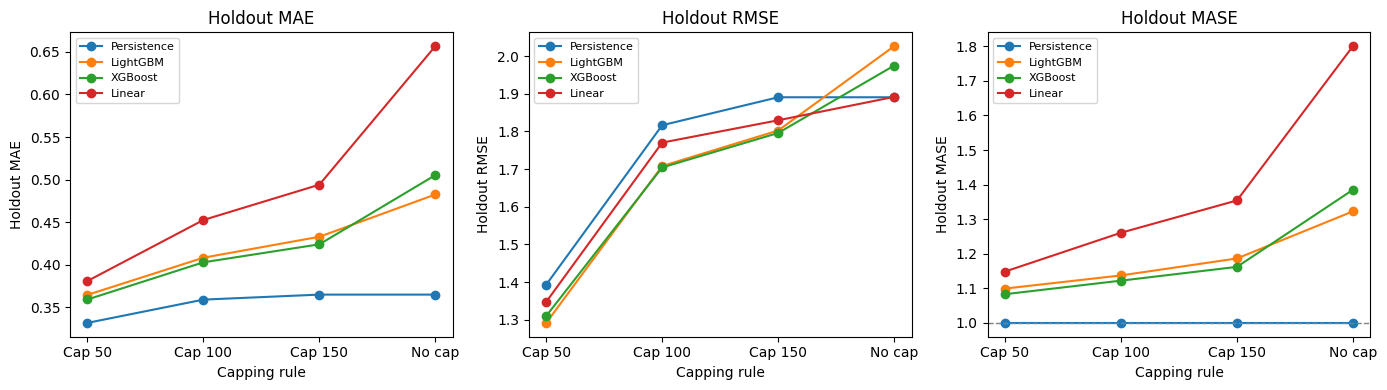

In [ ]:
import matplotlib.pyplot as plt

order = ["Cap 50", "Cap 100", "Cap 150", "No cap"]
metrics = ["mae", "rmse", "mase"]
titles = ["Holdout MAE", "Holdout RMSE", "Holdout MASE"]
models_to_plot = ["Persistence", "LightGBM", "XGBoost", "Linear"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)

for ax, metric, title in zip(axes, metrics, titles):
    for model in models_to_plot:
        subset = (
            pd.concat(cap_rows)
            .query("model == @model")
            .set_index("cap")
            .loc[order]
            .reset_index()
        )
        ax.plot(subset["cap"], subset[metric], marker="o", label=model)
    if metric == "mase":
        ax.axhline(1.0, color="gray", ls="--", lw=1)
    ax.set_ylabel(title)
    ax.set_xlabel("Capping rule")
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. Longer lead times

The same household split and feature set are reused. Only the target horizon changes.

- 30 minutes to the end of the target bin
- 60 minutes to the end of the target bin

Relative MAE is the ratio of each model’s MAE to the persistence baseline on the same horizon.

In [ ]:
from pathlib import Path

from IPython.display import display

from features import (
    KEYS, METADATA, load_bins, make_examples, feature_columns,
)
from models import (
    SEED, development_predictions, final_predictions, model_specs, select_models,
)
from evaluation import (
    onset_scores, paired_household_errors, score_predictions,
)

LEAD_MINUTES = 30
PM_CAP = 100.0
CV_FOLDS = 5
DATA_ROOT = Path("DATA")

HOLDOUT_IDS = {
    "007", "008", "013", "017", "025", "037", "040",
    "059", "101", "102", "116", "122", "127",
}
MAIN_GROUPS = ("calendar", "outdoor_pm", "ventilation", "environment")

# Reuse the 10-minute notebook's household split.
bins = load_bins(DATA_ROOT, min_valid_minutes=5)
reference = make_examples(bins, lead_minutes=10, cap=PM_CAP)
development_ids = set(reference["household_id"]) - HOLDOUT_IDS


# Reuse bins and the household split from the 30-minute cell.
examples_30 = make_examples(bins, lead_minutes=LEAD_MINUTES, cap=PM_CAP)
development_30 = examples_30.loc[
    examples_30["household_id"].isin(development_ids)
].copy()
holdout_30 = examples_30.loc[
    examples_30["household_id"].isin(HOLDOUT_IDS)
].copy()

features_30 = feature_columns(development_30, MAIN_GROUPS)
models_30, cv_30 = select_models(
    development_30, features_30, n_splits=CV_FOLDS
)

predictions_30 = final_predictions(holdout_30, models_30, features_30)
scores_30 = score_predictions(predictions_30, ["persistence", *models_30])

comparison_30 = (
    cv_30[["model", "cv_mae"]]
    .merge(scores_30, on="model", validate="one_to_one")
    .rename(columns={"mae": "holdout_mae", "rmse": "holdout_rmse"})
    .sort_values("holdout_mae")
    .reset_index(drop=True)
)

print(f"Lead time: {LEAD_MINUTES} minutes to the end of the target bin")
display(comparison_30.round(4))
# Build targets for the requested horizon and keep the 10-minute bin size.
examples = make_examples(bins, lead_minutes=LEAD_MINUTES, cap=PM_CAP)
development = examples.loc[examples["household_id"].isin(development_ids)].copy()
holdout = examples.loc[examples["household_id"].isin(HOLDOUT_IDS)].copy()
features = feature_columns(development, MAIN_GROUPS)

# Tune and refit on development homes, then score on held-out homes.
models, cv_results = select_models(development, features, n_splits=CV_FOLDS)
predictions = final_predictions(holdout, models, features)
holdout_results = score_predictions(predictions, ["persistence", *models])

comparison = (
    cv_results[["model", "cv_mae"]]
    .merge(holdout_results, on="model", validate="one_to_one")
    .rename(columns={"mae": "holdout_mae", "rmse": "holdout_rmse"})
    .sort_values("holdout_mae")
    .reset_index(drop=True)
)

print(f"Lead time: {LEAD_MINUTES} minutes to the end of the target bin")
print(f"Development: {development['household_id'].nunique()} homes, {len(development):,} forecasts")
print(f"Holdout: {holdout['household_id'].nunique()} homes, {len(holdout):,} forecasts")
display(comparison.round(4))

Lead time: 30 minutes to the end of the target bin


,model,cv_mae,holdout_mae,holdout_rmse,mase
0,Persistence,1.4391,0.7764,3.4284,1.0000
1,XGBoost,1.6807,1.0127,3.2029,1.3044
2,LightGBM,1.6728,1.0149,3.2043,1.3073
3,Linear,1.6780,1.1127,3.2900,1.4332
4,Ridge,1.6780,1.1127,3.2900,1.4332


Lead time: 30 minutes to the end of the target bin
Development: 55 homes, 50,560 forecasts
Holdout: 13 homes, 12,093 forecasts


,model,cv_mae,holdout_mae,holdout_rmse,mase
0,Persistence,1.4391,0.7764,3.4284,1.0000
1,XGBoost,1.6807,1.0127,3.2029,1.3044
2,LightGBM,1.6728,1.0149,3.2043,1.3073
3,Linear,1.6780,1.1127,3.2900,1.4332
4,Ridge,1.6780,1.1127,3.2900,1.4332


In [ ]:
LEAD_MINUTES = 60

# Reuse bins and the household split from the 60-minute cell.
examples_60 = make_examples(bins, lead_minutes=LEAD_MINUTES, cap=PM_CAP)
development_60 = examples_60.loc[
    examples_60["household_id"].isin(development_ids)
].copy()
holdout_60 = examples_60.loc[
    examples_60["household_id"].isin(HOLDOUT_IDS)
].copy()

features_60 = feature_columns(development_60, MAIN_GROUPS)
models_60, cv_60 = select_models(
    development_60, features_60, n_splits=CV_FOLDS
)

predictions_60 = final_predictions(holdout_60, models_60, features_60)
scores_60 = score_predictions(predictions_60, ["persistence", *models_60])

comparison_60 = (
    cv_60[["model", "cv_mae"]]
    .merge(scores_60, on="model", validate="one_to_one")
    .rename(columns={"mae": "holdout_mae", "rmse": "holdout_rmse"})
    .sort_values("holdout_mae")
    .reset_index(drop=True)
)

print(f"Lead time: {LEAD_MINUTES} minutes to the end of the target bin")
display(comparison_60.round(4))

Lead time: 60 minutes to the end of the target bin


,model,cv_mae,holdout_mae,holdout_rmse,mase
0,Persistence,2.4091,1.2509,4.7450,1.0000
1,LightGBM,2.6732,1.6768,4.2793,1.3404
2,XGBoost,2.6783,1.6870,4.2893,1.3487
3,Linear,2.7977,1.8576,4.3938,1.4850
4,Ridge,2.7977,1.8576,4.3938,1.4850


In [ ]:
LEAD_MINUTES = 10

# Reuse bins and the household split from the 10-minute cell.
examples_10 = make_examples(bins, lead_minutes=LEAD_MINUTES, cap=PM_CAP)
development_10 = examples_10.loc[
    examples_10["household_id"].isin(development_ids)
].copy()
holdout_10  = examples_10.loc[
    examples_10["household_id"].isin(HOLDOUT_IDS)
].copy()

features_10 = feature_columns(development_10, MAIN_GROUPS)
models_10, cv_10 = select_models(
    development_10, features_10, n_splits=CV_FOLDS
)

predictions_10 = final_predictions(holdout_10, models_10, features_10)
scores_10 = score_predictions(predictions_10, ["persistence", *models_10])

comparison_10 = (
    cv_10[["model", "cv_mae"]]
    .merge(scores_10, on="model", validate="one_to_one")
    .rename(columns={"mae": "holdout_mae", "rmse": "holdout_rmse"})
    .sort_values("holdout_mae")
    .reset_index(drop=True)
)

print(f"Lead time: {LEAD_MINUTES} minutes to the end of the target bin")
display(comparison_10.round(4))

Lead time: 10 minutes to the end of the target bin


,model,cv_mae,holdout_mae,holdout_rmse,mase
0,Persistence,0.6041,0.3589,1.8166,1.0000
1,XGBoost,0.6806,0.4028,1.7045,1.1222
2,LightGBM,0.6634,0.4082,1.7082,1.1373
3,Linear,0.6701,0.4525,1.7704,1.2607
4,Ridge,0.6701,0.4525,1.7704,1.2607


## Model performance by forecast horizon

Test RMSE is compared across the 10-, 30-, and 60-minute forecast horizons. Shorter horizons are easier to predict, and the grouped bars show how each model’s error grows as the lead time increases.

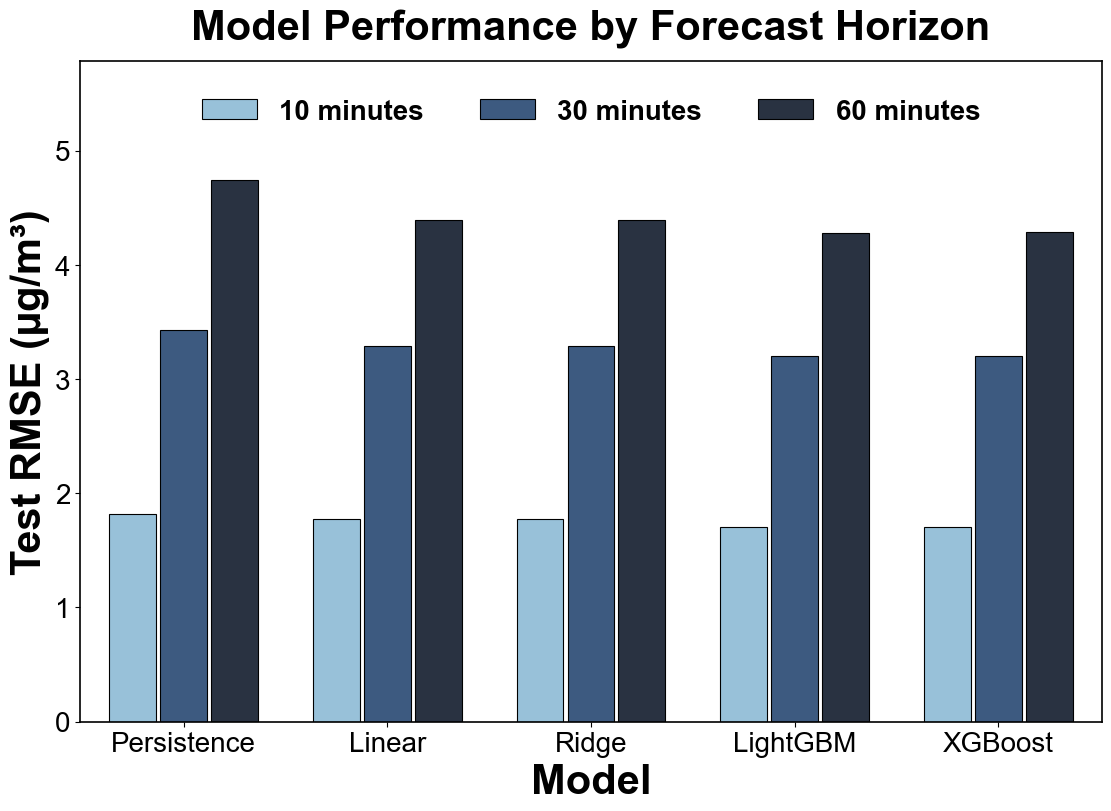

In [ ]:
## Model performance by forecast horizon

from plots import plot_rmse_by_horizon

# Build the RMSE-by-horizon table from the comparison results
rmse_by_horizon = pd.DataFrame({
    10: comparison_10.set_index("model")["holdout_rmse"],
    30: comparison_30.set_index("model")["holdout_rmse"],
    60: comparison_60.set_index("model")["holdout_rmse"],
}).T

# Make sure the model order matches the plot
rmse_by_horizon = rmse_by_horizon[
    ["Persistence", "Linear", "Ridge", "LightGBM", "XGBoost"]
]
plot_rmse_by_horizon(rmse_by_horizon)

## Observed vs predicted (XGBoost)

These scatter plots compare observed indoor PM₂.₅ with XGBoost predictions on the holdout homes. Points near the dashed line indicate good agreement. The panels show the 10-minute and 60-minute horizons side by side to illustrate how prediction quality changes with lead time.

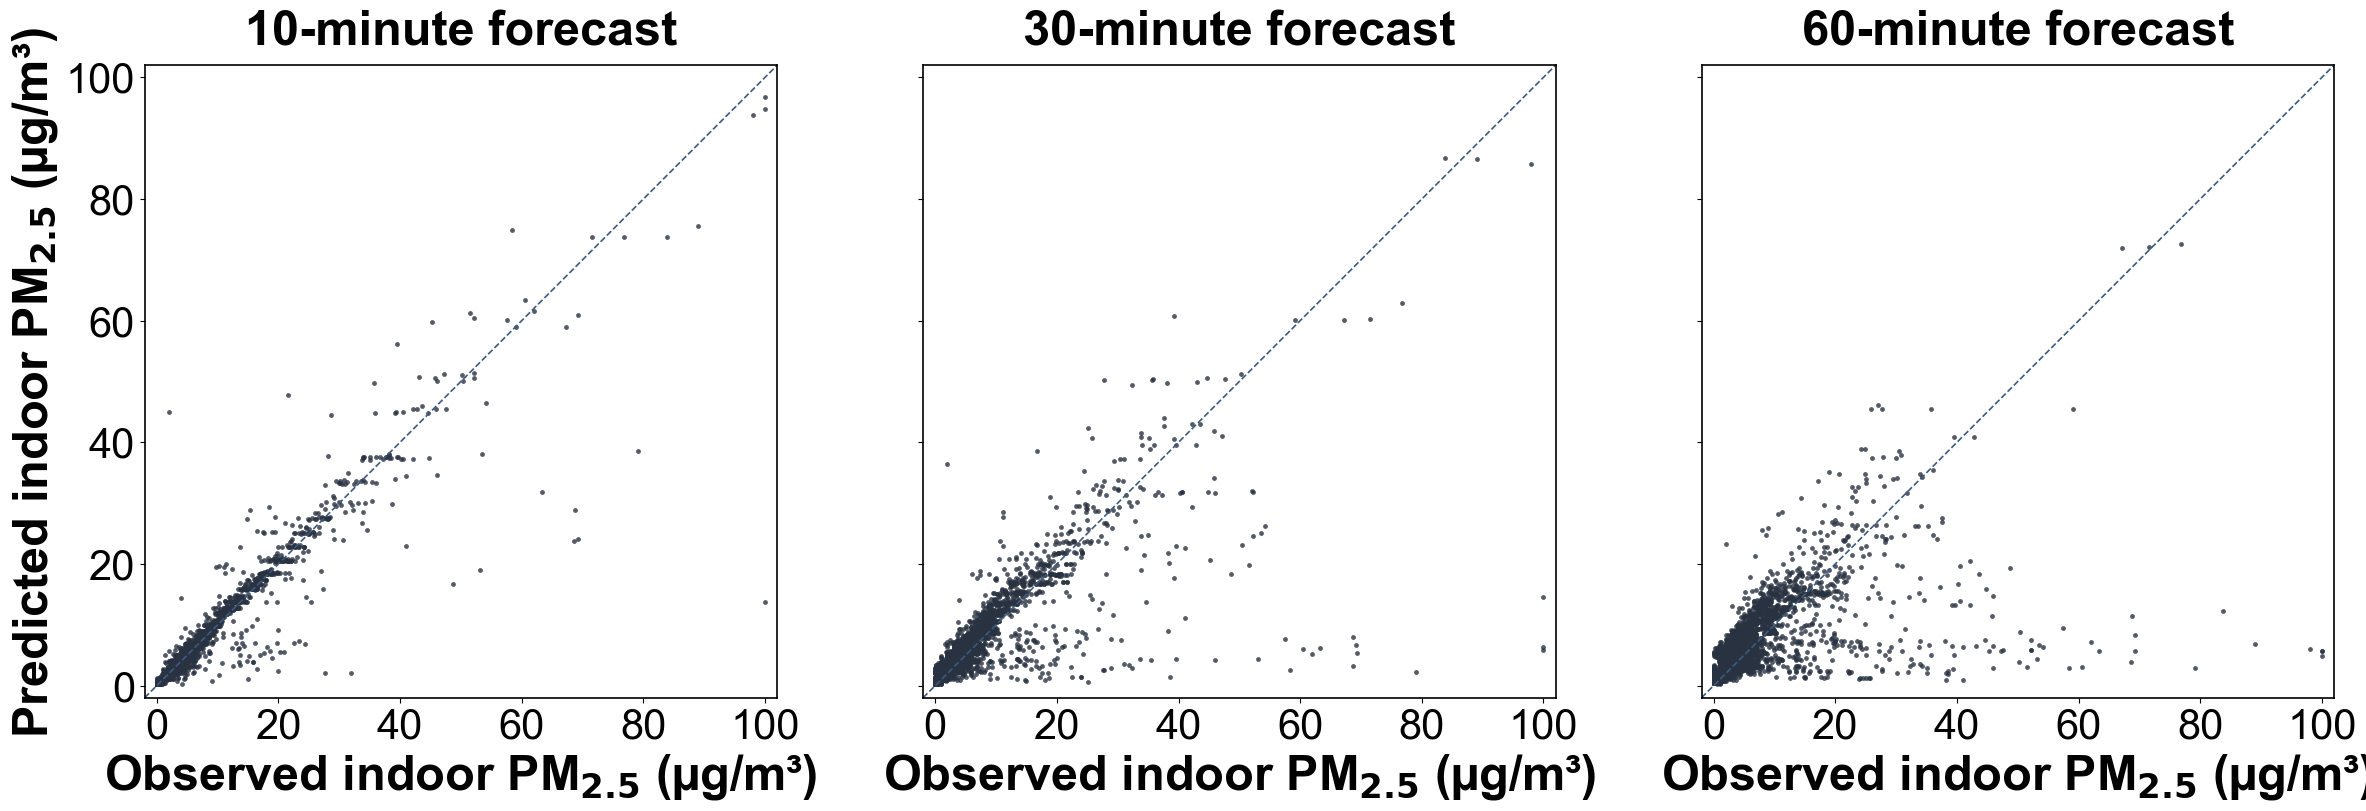

In [ ]:
## Observed vs predicted (XGBoost)

from plots import plot_xgboost_observed_vs_predicted

# Build the by_horizon dictionary from the prediction dataframes
by_horizon = {
    10: predictions_10,
    30: predictions_30,
    60: predictions_60,
}

plot_xgboost_observed_vs_predicted(by_horizon, horizons=(10, 30, 60))

## Additional Poster figures

These figures are prepared for the project poster. They illustrate data preprocessing, feature relationships, and model performance in a compact, presentation-ready style.

- **Preprocessing examples** show how raw minute-level PM₂.₅ is averaged into 10-minute bins, capped at 100 µg/m³, and filtered by minimum data coverage.
- **Correlation matrix** highlights the strongest relationships among the selected predictors.
- **Observed vs predicted** compares model predictions against measured indoor PM₂.₅ on the development set.

In [ ]:
from poster_figures import (
    plot_preprocessing_examples,
    plot_correlation_matrix,
    plot_observed_vs_predicted,
)

# 1. Preprocessing
plot_preprocessing_examples("DATA")

# 2. Correlation matrix (notebook that contains the snapshot)
plot_correlation_matrix("path/to/pearson_correlation.ipynb")

# 3. Observed vs predicted
plot_observed_vs_predicted(
    development["actual"],
    development["lightgbm"],
    model_name="LightGBM",
)